# Entrega final — Consolidación, interpretación y comunicación
### Proyecto Integrador · Machine Learning I · Universidad Externado de Colombia
**Localización interior mediante RSSI WiFi y la representación por cuartiles del artículo QA-kNN (Ferreira et al., 2020)**
**Sebastián Ramos · Daniel Cipagauta**

Este notebook es el anexo de código de la entrega final. Usa **solo datos reales**: el dataset **MNAV**, con escaneos WiFi tomados en las 16 salas del **Museo Nacional de Artes Visuales de Montevideo (Uruguay)**, publicado en GitHub con licencia MIT (`ffedee7/posifi_mnav`). Corre de principio a fin con `SEED = 42` y genera las figuras (`figuras_final/`) y las cifras (`resultados_final.json`).

| Sección | Contenido | Guía |
|---|---|---|
| 1 | Datos reales: carga, limpieza y estructura | 2.1 |
| 2 | Partición sin fuga e instancias por cuartiles | 2.1 |
| 3 | Comparación de modelos del curso | 2.1 |
| 4 | Estabilidad | 2.1 |
| 5 | Selección y configuración del modelo final | 2.1 |
| 6 | Reproducción de los objetivos del artículo | 2.1 |
| 7 | Interpretación del modelo final | 2.2 |
| 8 | Robustez | 2.4 |

**Declaración de uso de IA:** usamos un asistente de IA generativa (Claude, de Anthropic) como apoyo para estructurar el código y revisar la redacción. El equipo revisó y ejecutó cada resultado, y puede sustentar todas las decisiones.

In [1]:
import os, json, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score, cross_validate, train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
os.makedirs("figuras_final", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6"})
TINTA, GRIS = "#0b2e4f", "#898781"
COL = {"Línea base": GRIS, "kNN": "#2a78d6", "Naive Bayes": "#eb6834", "Logística Ridge (L2)": "#1baf7a",
       "Logística Lasso (L1)": "#0f7a4f", "LDA": "#e9a400", "QDA": "#d6559b"}
RES = {}
def guardar(fig, nombre): fig.savefig(f"figuras_final/{nombre}.png", bbox_inches="tight", facecolor="white")
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Datos reales: MNAV (Montevideo, Uruguay)
Cada fila es **un escaneo WiFi** hecho con un teléfono en una de las **16 salas** del museo, con el RSSI (dBm) de **188 APs** anonimizados; un 0 significa que el AP no se detectó en ese escaneo. Los datos no traen hora ni coordenadas: la etiqueta es la sala. Antes de partir eliminamos los escaneos **duplicados exactos**, para que un mismo escaneo no quede a la vez en entrenamiento y en prueba.

In [2]:
RUTA = "datos_mnav/anonym.csv"
if not os.path.exists(RUTA):
    os.makedirs("datos_mnav", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ffedee7/posifi_mnav/master/data_analysis/anonym.csv", RUTA)
crudo = pd.read_csv(RUTA, index_col=0)
APS_ALL = [c for c in crudo.columns if c != "location"]
crudo["sala"] = crudo.location.str.replace("location_", "", regex=False).astype(int).map(lambda n: f"S{n:02d}")
duplicado = crudo.duplicated(subset=APS_ALL + ["sala"])
esc = crudo[~duplicado].reset_index(drop=True)
NO_DET = -100.0                                   # un AP no detectado se representa por debajo de la sensibilidad
detectado = esc[APS_ALL] != 0
SALAS = sorted(esc.sala.unique())
RES["datos"] = dict(escaneos=len(crudo), duplicados=int(duplicado.sum()), escaneos_limpios=len(esc), salas=len(SALAS), aps=len(APS_ALL),
                    faltantes=int(crudo[APS_ALL].isna().sum().sum()),
                    escaneos_por_sala=esc.sala.value_counts().sort_index().to_dict(),
                    aps_detectados_por_escaneo_mediana=float(detectado.sum(axis=1).median()),
                    rssi_detectado=[float(esc[APS_ALL].where(detectado).min().min()), float(esc[APS_ALL].where(detectado).max().max())],
                    rssi_mediana=float(np.nanmedian(esc[APS_ALL].where(detectado).values)))
print(json.dumps({k: v for k, v in RES["datos"].items() if k != "escaneos_por_sala"}, indent=1))

{
 "escaneos": 10469,
 "duplicados": 2030,
 "escaneos_limpios": 8439,
 "salas": 16,
 "aps": 188,
 "faltantes": 0,
 "aps_detectados_por_escaneo_mediana": 22.0,
 "rssi_detectado": [
  -99.0,
  -28.0
 ],
 "rssi_mediana": -81.0
}


## 2. Partición sin fuga e instancias por cuartiles
1. **Primero se parte**: 20 % de los escaneos de cada sala para prueba (estratificado), y no se vuelve a tocar hasta el final.
2. **Selección de APs solo con entrenamiento**: usamos los APs que se detectan en al menos la mitad de los escaneos de entrenamiento. Los demás casi nunca aparecen y solo agregarían ruido.
3. **Instancias como en el artículo**: cada instancia agrupa **m = 5 escaneos de la misma sala** y los resume, por AP, en Q1, Q2 y Q3. Los grupos se forman por separado dentro de entrenamiento y dentro de prueba, así que ningún escaneo aporta a ambos lados.
4. La validación cruzada es estratificada (5 pliegues) sobre las instancias de entrenamiento, y todo el preprocesamiento va dentro del Pipeline.

**Escenario principal: los 4 APs más frecuentes.** Con los 20 APs frecuentes todos los modelos aciertan prácticamente el 100 % (Sección 6), y no habría nada que comparar ni interpretar. Cuatro APs es la configuración con la que el artículo reporta su mejor resultado, y es el caso de bajo costo; los elegimos por su frecuencia de detección en entrenamiento, sin mirar la prueba.

In [3]:
esc_tr, esc_te = train_test_split(esc, test_size=0.2, stratify=esc.sala, random_state=SEED)
frec = (esc_tr[APS_ALL] != 0).mean().sort_values(ascending=False)
APS_SEL = list(frec[frec >= 0.5].index)
NOMBRE = {a: f"AP{i+1:02d}" for i, a in enumerate(APS_SEL)}      # AP01 = el más frecuente en entrenamiento
M_ESC = 5

def agrupar(df, m=M_ESC, seed=SEED, aps=APS_SEL):
    """Una instancia por grupo de m escaneos de la misma sala: Q1, Q2, Q3, media y un escaneo suelto por AP."""
    rng = np.random.default_rng(seed); filas = []
    for sala, g in df.groupby("sala"):
        v = g[aps].replace(0, NO_DET).values[rng.permutation(len(g))]
        for b in range(len(v) // m):
            blk = v[b*m:(b+1)*m]; f = dict(sala=sala)
            q1, q2, q3 = np.percentile(blk, [25, 50, 75], axis=0)
            for j, a in enumerate(aps):
                n = NOMBRE[a]; f.update({f"{n}_Q1": q1[j], f"{n}_Q2": q2[j], f"{n}_Q3": q3[j], f"{n}_media": blk[:, j].mean(), f"{n}_cruda": blk[0, j]})
            filas.append(f)
    return pd.DataFrame(filas)

def columnas(rep, n_aps=None):
    nombres = [NOMBRE[a] for a in APS_SEL][:n_aps]
    if rep == "cuartiles": return [f"{n}_{q}" for n in nombres for q in ("Q1", "Q2", "Q3")]
    suf = {"media": "media", "mediana": "Q2", "cruda": "cruda", "Q1": "Q1", "Q3": "Q3"}[rep]
    return [f"{n}_{suf}" for n in nombres]

tr, te = agrupar(esc_tr), agrupar(esc_te)
N_MAIN = 4
FEATS = columnas("cuartiles", N_MAIN)
Xtr, ytr, Xte, yte = tr[FEATS], tr.sala.to_numpy(dtype=str), te[FEATS], te.sala.to_numpy(dtype=str)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"f1": "f1_macro", "accuracy": "accuracy", "bal": "balanced_accuracy"}
RES["particion"] = dict(escaneos_entrenamiento=len(esc_tr), escaneos_prueba=len(esc_te), aps_seleccionados=len(APS_SEL), aps_principales=N_MAIN, variables=len(FEATS),
                        m_escaneos=M_ESC, instancias_entrenamiento=len(tr), instancias_prueba=len(te),
                        instancias_por_sala_min=int(tr.sala.value_counts().min()), instancias_por_sala_max=int(tr.sala.value_counts().max()),
                        frecuencia_deteccion_sel=[round(float(frec[a]), 2) for a in APS_SEL])
print(json.dumps(RES["particion"], indent=1))

{
 "escaneos_entrenamiento": 6751,
 "escaneos_prueba": 1688,
 "aps_seleccionados": 20,
 "aps_principales": 4,
 "variables": 12,
 "m_escaneos": 5,
 "instancias_entrenamiento": 1344,
 "instancias_prueba": 331,
 "instancias_por_sala_min": 47,
 "instancias_por_sala_max": 146,
 "frecuencia_deteccion_sel": [
  1.0,
  0.99,
  0.98,
  0.96,
  0.93,
  0.92,
  0.89,
  0.89,
  0.88,
  0.87,
  0.83,
  0.8,
  0.79,
  0.79,
  0.79,
  0.77,
  0.75,
  0.73,
  0.58,
  0.58
 ]
}


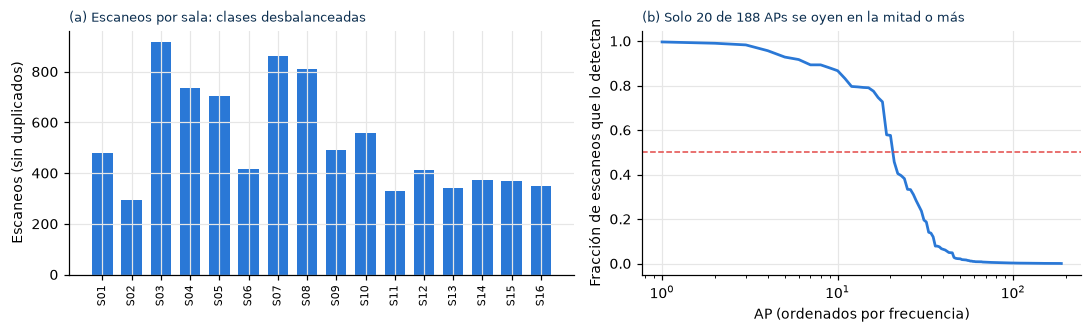

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.1), gridspec_kw=dict(width_ratios=[1.15, 1]))
cnt = esc.sala.value_counts().sort_index()
ax[0].bar(cnt.index, cnt.values, color="#2a78d6", width=0.7)
ax[0].set_ylabel("Escaneos (sin duplicados)"); ax[0].tick_params(axis="x", labelsize=7, rotation=90)
ax[0].set_title("(a) Escaneos por sala: clases desbalanceadas", loc="left", fontsize=8.5, color=TINTA)
ax[1].plot(range(1, len(frec) + 1), frec.values, color="#2a78d6", lw=1.8)
ax[1].axhline(0.5, color="#e34948", ls="--", lw=1); ax[1].set_xscale("log")
ax[1].set_xlabel("AP (ordenados por frecuencia)"); ax[1].set_ylabel("Fracción de escaneos que lo detectan")
ax[1].set_title(f"(b) Solo {len(APS_SEL)} de {len(APS_ALL)} APs se oyen en la mitad o más", loc="left", fontsize=8.5, color=TINTA)
fig.tight_layout(); guardar(fig, "f1_datos"); plt.show()

## 3. Comparación de modelos del curso
Mismo Pipeline para todos (imputación → escalado → modelo) y `GridSearchCV`. QDA necesita regularización (*shrinkage*): algunas salas tienen menos instancias que variables y su covarianza propia no se puede estimar sin ella. Como las salas están **desbalanceadas** (la más grande tiene unas tres veces los escaneos de la más chica), el criterio principal es el **F1-macro**, que pesa igual a todas las salas. Reportamos también el acierto y el acierto balanceado. La línea base predice siempre la sala más frecuente.

In [5]:
def pipe(modelo, escalar=True):
    return Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler() if escalar else "passthrough"), ("modelo", modelo)])
MODELOS = {
    "Línea base": (pipe(DummyClassifier(strategy="most_frequent"), False), {}),
    "kNN": (pipe(KNeighborsClassifier()), {"escalar": [StandardScaler(), "passthrough"], "modelo__n_neighbors": list(range(1, 26, 2)),
                                           "modelo__weights": ["uniform", "distance"], "modelo__p": [1, 2]}),
    "Naive Bayes": (pipe(GaussianNB(), False), {"modelo__var_smoothing": list(np.logspace(-9, -1, 9))}),
    "Logística Ridge (L2)": (pipe(LogisticRegression(max_iter=10000)), {"modelo__C": list(np.logspace(-3, 2, 6))}),
    "Logística Lasso (L1)": (pipe(LogisticRegression(l1_ratio=1.0, solver="saga", max_iter=5000, tol=1e-3)), {"modelo__C": [0.03, 0.1, 0.3, 1.0, 3.0]}),
    "LDA": (pipe(LinearDiscriminantAnalysis(solver="lsqr")), {"modelo__shrinkage": [None, "auto", 0.05, 0.1, 0.2, 0.4]}),
    "QDA": (pipe(QuadraticDiscriminantAnalysis(solver="eigen")), {"modelo__shrinkage": ["auto", 0.05, 0.1, 0.2, 0.4, 0.6]}),
}
def bootstrap(yt, yp, f, n=1000, seed=SEED):
    rng = np.random.default_rng(seed); i = np.arange(len(yt))
    v = [f(yt[s], yp[s]) for s in (rng.choice(i, len(i)) for _ in range(n))]
    return [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]
f1m = lambda a, b: f1_score(a, b, average="macro")
BUSQ, filas = {}, []
for nombre, (modelo, grid) in MODELOS.items():
    gs = GridSearchCV(modelo, grid, scoring=SCORING, refit="f1", cv=CV).fit(Xtr, ytr)
    BUSQ[nombre] = gs; r, i = gs.cv_results_, gs.best_index_; yp = gs.best_estimator_.predict(Xte)
    params = {k.replace("modelo__", ""): (type(v).__name__ if not isinstance(v, (int, float, str, type(None))) else v) for k, v in gs.best_params_.items()}
    filas.append(dict(Modelo=nombre, mejores=params, f1=r["mean_test_f1"][i], f1_sd=r["std_test_f1"][i], acc=r["mean_test_accuracy"][i],
                      bal=r["mean_test_bal"][i], folds=[r[f"split{k}_test_f1"][i] for k in range(5)],
                      f1_te=f1m(yte, yp), f1_ic=bootstrap(yte, yp, f1m), acc_te=accuracy_score(yte, yp), acc_ic=bootstrap(yte, yp, accuracy_score),
                      bal_te=balanced_accuracy_score(yte, yp)))
    print(f"{nombre:22s} F1 CV {filas[-1]['f1']:.3f} ± {filas[-1]['f1_sd']:.3f} | acc CV {filas[-1]['acc']:.3f} | F1 prueba {filas[-1]['f1_te']:.3f} | {params}")
resumen = pd.DataFrame(filas)
PRED = {n: BUSQ[n].best_estimator_.predict(Xte) for n in BUSQ}
RES["comparacion"] = resumen.to_dict(orient="records")

Línea base             F1 CV 0.012 ± 0.000 | acc CV 0.109 | F1 prueba 0.012 | {}


kNN                    F1 CV 0.952 ± 0.010 | acc CV 0.938 | F1 prueba 0.964 | {'escalar': 'passthrough', 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}


Naive Bayes            F1 CV 0.955 ± 0.004 | acc CV 0.943 | F1 prueba 0.957 | {'var_smoothing': np.float64(1e-09)}


Logística Ridge (L2)   F1 CV 0.945 ± 0.015 | acc CV 0.932 | F1 prueba 0.971 | {'C': np.float64(10.0)}


Logística Lasso (L1)   F1 CV 0.940 ± 0.008 | acc CV 0.929 | F1 prueba 0.966 | {'C': 3.0}


LDA                    F1 CV 0.953 ± 0.009 | acc CV 0.940 | F1 prueba 0.959 | {'shrinkage': None}


QDA                    F1 CV 0.959 ± 0.007 | acc CV 0.946 | F1 prueba 0.964 | {'shrinkage': 0.4}


## 4. Estabilidad
Tres fuentes de variación: los **pliegues** de la validación cruzada (arriba), **cómo se agrupan los escaneos** en instancias (5 agrupamientos distintos) y **qué 4 APs se usan** (30 combinaciones al azar entre los 20 frecuentes). Todo con los hiperparámetros ya elegidos y solo con entrenamiento.

In [6]:
estab = []
for s in [1, 2, 3, 4, 5]:
    tr_s = agrupar(esc_tr, seed=s)
    for nombre in [n for n in BUSQ if n != "Línea base"]:
        v = cross_val_score(clone(BUSQ[nombre].best_estimator_), tr_s[FEATS], tr_s.sala.to_numpy(dtype=str), cv=CV, scoring="f1_macro")
        estab.append(dict(semilla=s, Modelo=nombre, f1=v.mean()))
estab = pd.DataFrame(estab); piv = estab.pivot(index="semilla", columns="Modelo", values="f1")
gana = piv.idxmax(axis=1).value_counts()
rng_c = np.random.default_rng(SEED); nombres_sel = [NOMBRE[a] for a in APS_SEL]; combos = []
while len(combos) < 30:
    c = tuple(sorted(rng_c.choice(len(nombres_sel), N_MAIN, replace=False)))
    if c not in combos: combos.append(c)
est_ap = []
for c in combos:
    cols = [f"{nombres_sel[j]}_{q}" for j in c for q in ("Q1", "Q2", "Q3")]
    for nombre in [n for n in BUSQ if n != "Línea base"]:
        v = cross_val_score(clone(BUSQ[nombre].best_estimator_), tr[cols], ytr, cv=CV, scoring="f1_macro")
        est_ap.append(dict(combo=str(c), Modelo=nombre, f1=v.mean()))
est_ap = pd.DataFrame(est_ap); piv_ap = est_ap.pivot(index="combo", columns="Modelo", values="f1"); gana_ap = piv_ap.idxmax(axis=1).value_counts()
RES["estabilidad"] = {n: dict(media=round(float(piv[n].mean()), 4), de=round(float(piv[n].std()), 4), veces_primero=int(gana.get(n, 0)),
                              combos_media=round(float(piv_ap[n].mean()), 4), combos_de=round(float(piv_ap[n].std()), 4),
                              combos_min=round(float(piv_ap[n].min()), 4), combos_veces_primero=int(gana_ap.get(n, 0))) for n in piv.columns}
print(pd.DataFrame(RES["estabilidad"]).T.sort_values("media", ascending=False))

                       media      de  veces_primero  combos_media  combos_de  \
QDA                   0.9619  0.0060            5.0        0.9347     0.0273   
Naive Bayes           0.9537  0.0055            0.0        0.9015     0.0416   
LDA                   0.9536  0.0069            0.0        0.9156     0.0302   
kNN                   0.9500  0.0066            0.0        0.9241     0.0334   
Logística Ridge (L2)  0.9482  0.0046            0.0        0.9283     0.0296   
Logística Lasso (L1)  0.9467  0.0026            0.0        0.9268     0.0294   

                      combos_min  combos_veces_primero  
QDA                       0.8701                  22.0  
Naive Bayes               0.8227                   0.0  
LDA                       0.8597                   0.0  
kNN                       0.8241                   1.0  
Logística Ridge (L2)      0.8623                   5.0  
Logística Lasso (L1)      0.8641                   2.0  


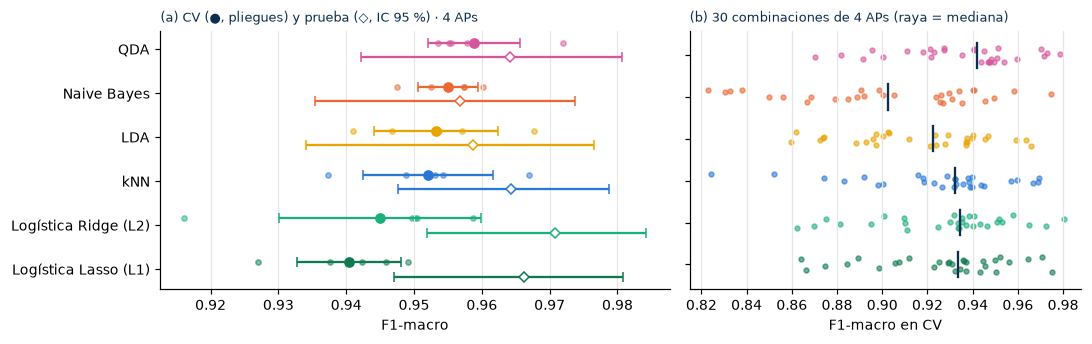

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw=dict(width_ratios=[1.3, 1]))
orden = [n for n in resumen.sort_values("f1").Modelo if n != "Línea base"]
for i, n in enumerate(orden):
    f = resumen[resumen.Modelo == n].iloc[0]
    ax[0].scatter(f.folds, [i + 0.15] * 5, s=12, color=COL[n], alpha=0.5)
    ax[0].errorbar(f.f1, i + 0.15, xerr=f.f1_sd, fmt="o", ms=6, color=COL[n], capsize=3)
    ax[0].errorbar(f.f1_te, i - 0.18, xerr=[[f.f1_te - f.f1_ic[0]], [f.f1_ic[1] - f.f1_te]], fmt="D", ms=5, mfc="white", color=COL[n], capsize=3)
ax[0].set_yticks(range(len(orden)), orden); ax[0].set_xlabel("F1-macro"); ax[0].grid(axis="y", visible=False)
ax[0].set_title("(a) CV (●, pliegues) y prueba (◇, IC 95 %) · 4 APs", loc="left", fontsize=8.5, color=TINTA)
for i, n in enumerate(orden):
    v = piv_ap[n].values; ax[1].scatter(v, i + np.random.default_rng(i).uniform(-0.18, 0.18, len(v)), s=10, color=COL[n], alpha=0.6)
    ax[1].plot([np.median(v)] * 2, [i - 0.3, i + 0.3], color=TINTA, lw=1.5)
ax[1].set_yticks(range(len(orden)), []); ax[1].set_xlabel("F1-macro en CV"); ax[1].grid(axis="y", visible=False)
ax[1].set_title("(b) 30 combinaciones de 4 APs (raya = mediana)", loc="left", fontsize=8.5, color=TINTA)
fig.tight_layout(); guardar(fig, "f2_comparacion"); plt.show()

## 5. Selección del modelo final
**El criterio es el F1-macro en validación cruzada** (a igualdad, el mayor acierto y luego el modelo más simple). La prueba no interviene en la elección: se usa después para confirmarla.

In [8]:
cands = resumen[resumen.Modelo != "Línea base"].copy()
cands["f1_r"] = cands.f1.round(3)
cands = cands.sort_values(["f1_r", "acc"], ascending=[False, False])
FINAL = cands.Modelo.iloc[0]
def mcnemar(a, b):
    ok_a, ok_b = PRED[a] == yte, PRED[b] == yte
    n01, n10 = int(np.sum(ok_a & ~ok_b)), int(np.sum(~ok_a & ok_b))
    return [n01, n10, float(stats.binomtest(n01, n01 + n10, 0.5).pvalue) if n01 + n10 else 1.0]
RES["final"] = FINAL; RES["final_params"] = {k: str(v) for k, v in BUSQ[FINAL].best_params_.items()}
RES["mcnemar"] = {f"{FINAL} vs {o}": mcnemar(FINAL, o) for o in cands.Modelo if o != FINAL}
decision = cands.set_index("Modelo")[["f1", "f1_sd", "acc", "f1_te", "acc_te", "bal_te"]].round(3)
decision["estab_media"] = [RES["estabilidad"][n]["media"] for n in decision.index]
decision["combos_media"] = [RES["estabilidad"][n]["combos_media"] for n in decision.index]
RES["decision"] = decision.reset_index().to_dict(orient="list")
print("Modelo final:", FINAL, BUSQ[FINAL].best_params_); print(json.dumps(RES["mcnemar"], indent=1, ensure_ascii=False)); decision

Modelo final: QDA {'modelo__shrinkage': 0.4}
{
 "QDA vs Naive Bayes": [
  8,
  5,
  0.5810546875
 ],
 "QDA vs LDA": [
  7,
  6,
  1.0
 ],
 "QDA vs kNN": [
  6,
  4,
  0.75390625
 ],
 "QDA vs Logística Ridge (L2)": [
  4,
  6,
  0.75390625
 ],
 "QDA vs Logística Lasso (L1)": [
  7,
  7,
  1.0
 ]
}


,f1,f1_sd,acc,f1_te,acc_te,bal_te,estab_media,combos_media
Modelo,,,,,,,,
QDA,0.959,0.007,0.946,0.964,0.952,0.966,0.9619,0.9347
Naive Bayes,0.955,0.004,0.943,0.957,0.943,0.958,0.9537,0.9015
LDA,0.953,0.009,0.940,0.959,0.949,0.959,0.9536,0.9156
kNN,0.952,0.010,0.938,0.964,0.946,0.965,0.9500,0.9241
Logística Ridge (L2),0.945,0.015,0.932,0.971,0.958,0.971,0.9482,0.9283
Logística Lasso (L1),0.940,0.008,0.929,0.966,0.952,0.967,0.9467,0.9268


In [9]:
# Supuestos que distinguen a NB, LDA y QDA (solo entrenamiento)
lev = [stats.levene(*[tr.loc[tr.sala == s, f].values for s in SALAS], center="median").pvalue for f in FEATS]
de_sala = tr.groupby("sala")[FEATS].std()
razon = (de_sala.max() / de_sala.replace(0, np.nan).min()).median()
nombres = [NOMBRE[a] for a in APS_SEL][:N_MAIN]
corr_q = np.nanmean([tr.groupby("sala")[[f"{n}_Q1", f"{n}_Q3"]].corr().xs(f"{n}_Q1", level=1)[f"{n}_Q3"].mean() for n in nombres])
corr_ap = np.nanmean(np.abs(tr.groupby("sala")[columnas("mediana", N_MAIN)].corr().values[~np.eye(len(nombres) * len(SALAS), len(nombres), dtype=bool)]))
RES["supuestos"] = dict(levene_rechazo_pct=round(100 * float(np.mean(np.array(lev) < 0.05)), 1), razon_de_mediana=round(float(razon), 2),
                        corr_q1_q3_mismo_ap=round(float(corr_q), 2), corr_abs_entre_aps=round(float(corr_ap), 2))
print(RES["supuestos"])

{'levene_rechazo_pct': 100.0, 'razon_de_mediana': 2.95, 'corr_q1_q3_mismo_ap': 0.47, 'corr_abs_entre_aps': 0.38}


## 6. Reproducción de los objetivos del artículo
**6.1 Número de APs × k** (Tabla 3 del artículo), con kNN y los APs más frecuentes. El dataset no trae coordenadas, así que medimos acierto, no metros. Al final se evalúan en prueba todos los modelos con los 20 APs.

In [10]:
bpk = BUSQ["kNN"].best_params_
def knn_pipe(k=None):
    p = clone(BUSQ["kNN"].best_estimator_)
    return p.set_params(modelo__n_neighbors=k) if k else p
NS = [n for n in [2, 3, 4, 6, 8, 12, 16] if n < len(APS_SEL)] + [len(APS_SEL)]
barr = []
for n in NS:
    cols = columnas("cuartiles", n)
    for k in [1, 3, 5, 9, 15, 25]:
        s = cross_validate(knn_pipe(k), tr[cols], ytr, cv=CV, scoring=SCORING)
        barr.append(dict(n=n, k=k, f1=s["test_f1"].mean(), acc=s["test_accuracy"].mean()))
barr = pd.DataFrame(barr); RES["barrido_nk"] = barr.round(4).values.tolist()
c20 = columnas("cuartiles")
RES["con_20_aps_prueba"] = {n: float(f1m(yte, clone(BUSQ[n].best_estimator_).fit(tr[c20], ytr).predict(te[c20]))) for n in BUSQ}
print(RES["con_20_aps_prueba"])
print(barr.pivot(index="n", columns="k", values="acc").round(3))

{'Línea base': 0.01226158038147139, 'kNN': 1.0, 'Naive Bayes': 0.9956896551724138, 'Logística Ridge (L2)': 1.0, 'Logística Lasso (L1)': 0.9979578392621871, 'LDA': 0.9966525722339676, 'QDA': 1.0}
k      1      3      5      9      15     25
n                                           
2   0.583  0.602  0.632  0.648  0.654  0.658
3   0.828  0.847  0.856  0.855  0.859  0.859
4   0.920  0.929  0.938  0.935  0.935  0.929
6   0.943  0.952  0.958  0.954  0.961  0.958
8   0.981  0.985  0.989  0.989  0.990  0.987
12  0.993  0.993  0.995  0.995  0.993  0.995
16  0.996  0.996  0.997  0.998  0.996  0.997
20  0.999  0.999  0.999  0.997  0.997  0.998


**6.2 ¿Ayudan los cuartiles?** Misma kNN, distintas formas de resumir los 5 escaneos de cada AP, y un escaneo suelto. **6.3 Un solo cuartil**, el trabajo futuro que proponen los autores.

In [11]:
rep_res = []
for n in [2, 3, 4, 6, 12, len(APS_SEL)]:
    for rep in ["cruda", "media", "mediana", "Q1", "Q3", "cuartiles"]:
        s = cross_validate(knn_pipe(), tr[columnas(rep, n)], ytr, cv=CV, scoring=SCORING)
        rep_res.append(dict(n=n, rep=rep, f1=s["test_f1"].mean(), acc=s["test_accuracy"].mean()))
rep_res = pd.DataFrame(rep_res); RES["representaciones"] = rep_res.round(4).values.tolist()
print(rep_res.pivot(index="n", columns="rep", values="f1").round(3))

rep     Q1     Q3  cruda  cuartiles  media  mediana
n                                                  
2    0.521  0.582  0.351      0.642  0.626    0.552
3    0.783  0.844  0.555      0.880  0.894    0.825
4    0.875  0.919  0.657      0.952  0.957    0.918
6    0.916  0.955  0.732      0.968  0.970    0.942
12   0.982  0.995  0.872      0.996  0.992    0.994
20   0.991  0.997  0.923      0.999  0.996    0.995


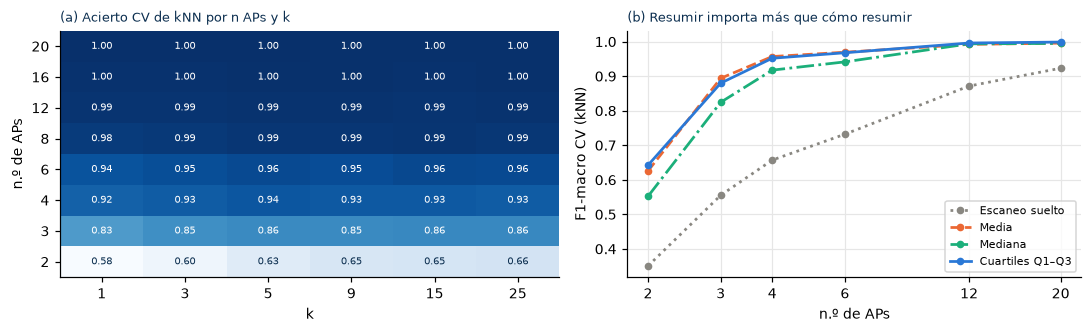

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.1), gridspec_kw=dict(width_ratios=[1.1, 1]))
pv = barr.pivot(index="n", columns="k", values="acc")
ax[0].imshow(pv.values, cmap="Blues", aspect="auto", origin="lower", vmin=pv.values.min(), vmax=1)
ax[0].set_xticks(range(pv.shape[1]), pv.columns); ax[0].set_yticks(range(pv.shape[0]), pv.index); ax[0].grid(False)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        val = pv.values[i, j]; ax[0].text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=6.5, color="white" if val > (pv.values.min() + 1) / 2 else TINTA)
ax[0].set_xlabel("k"); ax[0].set_ylabel("n.º de APs"); ax[0].set_title("(a) Acierto CV de kNN por n APs y k", loc="left", fontsize=8.5, color=TINTA)
est = {"cruda": ("#898781", ":", "Escaneo suelto"), "media": ("#eb6834", "--", "Media"), "mediana": ("#1baf7a", "-.", "Mediana"), "cuartiles": ("#2a78d6", "-", "Cuartiles Q1–Q3")}
for rep, (c, ls, et) in est.items():
    s = rep_res[rep_res.rep == rep]; ax[1].plot(s.n, s.f1, ls, marker="o", ms=4, color=c, lw=1.8, label=et)
ax[1].set_xlabel("n.º de APs"); ax[1].set_ylabel("F1-macro CV (kNN)"); ax[1].legend(fontsize=7)
ax[1].set_xscale("log"); ax[1].set_xticks(sorted(rep_res.n.unique()), sorted(rep_res.n.unique())); ax[1].minorticks_off()
ax[1].set_title("(b) Resumir importa más que cómo resumir", loc="left", fontsize=8.5, color=TINTA)
fig.tight_layout(); guardar(fig, "f3_articulo"); plt.show()

## 7. Interpretación del modelo final
Dónde falla (matriz de confusión), qué información usa (importancia por permutación) y, como lectura complementaria, los **coeficientes de una logística sobre la mediana de cada AP**: qué APs «delatan» cada sala.

In [13]:
mf = BUSQ[FINAL].best_estimator_; ypf = PRED[FINAL]
cm = confusion_matrix(yte, ypf, labels=SALAS)
pares = sorted([(SALAS[i], SALAS[j], int(cm[i, j])) for i in range(len(SALAS)) for j in range(len(SALAS)) if i != j and cm[i, j]], key=lambda t: -t[2])
recall = {s: round(float(cm[i, i] / cm[i].sum()), 3) for i, s in enumerate(SALAS)}
simetricos = sorted({tuple(sorted((a, b))) for a, b, c in pares if cm[SALAS.index(b), SALAS.index(a)] > 0})
def imp_perm(modelo, X, y, grupos, n_rep=15, seed=SEED):
    rng = np.random.default_rng(seed); base = f1m(y, modelo.predict(X)); out = {}
    for nombre, cols in grupos.items():
        c = []
        for _ in range(n_rep):
            Xp = X.copy(); Xp[cols] = X[cols].values[rng.permutation(len(X))]; c.append(base - f1m(y, modelo.predict(Xp)))
        out[nombre] = [float(np.mean(c)), float(np.std(c))]
    return out
imp_ap = imp_perm(mf, Xte, yte, {n: [f"{n}_Q1", f"{n}_Q2", f"{n}_Q3"] for n in nombres})
imp_q = imp_perm(mf, Xte, yte, {q: [f"{n}_{q}" for n in nombres] for q in ("Q1", "Q2", "Q3")})
top_ap = sorted(imp_ap, key=lambda k: -imp_ap[k][0])
RES["interpretacion"] = dict(modelo=FINAL, errores=int((ypf != yte).sum()), prueba=len(yte), recall_por_sala=recall, pares_confundidos=pares[:10],
                             confusiones_en_ambos_sentidos=[list(p) for p in simetricos], importancia_AP=imp_ap, importancia_cuartil=imp_q, top_aps=top_ap[:5])
# Lectura complementaria: logística L2 sobre la mediana estandarizada de cada AP
cq2 = columnas("mediana", N_MAIN)
lg = pipe(LogisticRegression(C=1.0, max_iter=20000)).fit(tr[cq2], ytr)
B = pd.DataFrame(lg.named_steps["modelo"].coef_, index=lg.classes_, columns=nombres)
media_sala = esc_tr.assign(**{NOMBRE[a]: esc_tr[a].replace(0, NO_DET) for a in APS_SEL}).groupby("sala")[nombres].mean()
rho = float(stats.spearmanr(B.values.ravel(), (media_sala.loc[B.index, nombres] - media_sala[nombres].mean()).values.ravel()).statistic)
firma = {s: B.loc[s].sort_values(ascending=False).index[:2].tolist() for s in B.index}
mas_fuerte = {s: media_sala.loc[s, nombres].idxmax() for s in B.index}
RES["logistica_mediana"] = dict(f1_prueba=float(f1m(yte, lg.predict(te[cq2]))), spearman_coef_vs_senal_relativa=round(rho, 2), firma=firma,
                                firma_coincide_con_ap_mas_fuerte=int(sum(firma[s][0] == mas_fuerte[s] for s in firma)))
print(json.dumps({k: RES["interpretacion"][k] for k in ("errores", "prueba", "pares_confundidos", "confusiones_en_ambos_sentidos", "top_aps")}, indent=1, ensure_ascii=False))
print({s: r for s, r in recall.items() if r < 0.95}); print(json.dumps(RES["logistica_mediana"], indent=1, ensure_ascii=False))

{
 "errores": 16,
 "prueba": 331,
 "pares_confundidos": [
  [
   "S07",
   "S03",
   5
  ],
  [
   "S03",
   "S07",
   3
  ],
  [
   "S08",
   "S06",
   2
  ],
  [
   "S01",
   "S09",
   1
  ],
  [
   "S03",
   "S08",
   1
  ],
  [
   "S05",
   "S07",
   1
  ],
  [
   "S07",
   "S05",
   1
  ],
  [
   "S08",
   "S09",
   1
  ],
  [
   "S11",
   "S10",
   1
  ]
 ],
 "confusiones_en_ambos_sentidos": [
  [
   "S03",
   "S07"
  ],
  [
   "S05",
   "S07"
  ]
 ],
 "top_aps": [
  "AP04",
  "AP03",
  "AP01",
  "AP02"
 ]
}
{'S01': 0.947, 'S03': 0.889, 'S07': 0.824, 'S08': 0.906, 'S11': 0.923}
{
 "f1_prueba": 0.9190712047595029,
 "spearman_coef_vs_senal_relativa": 0.95,
 "firma": {
  "S01": [
   "AP02",
   "AP01"
  ],
  "S02": [
   "AP02",
   "AP01"
  ],
  "S03": [
   "AP01",
   "AP04"
  ],
  "S04": [
   "AP03",
   "AP01"
  ],
  "S05": [
   "AP04",
   "AP03"
  ],
  "S06": [
   "AP01",
   "AP02"
  ],
  "S07": [
   "AP04",
   "AP01"
  ],
  "S08": [
   "AP01",
   "AP04"
  ],
  "S09": [
   "AP02",
 

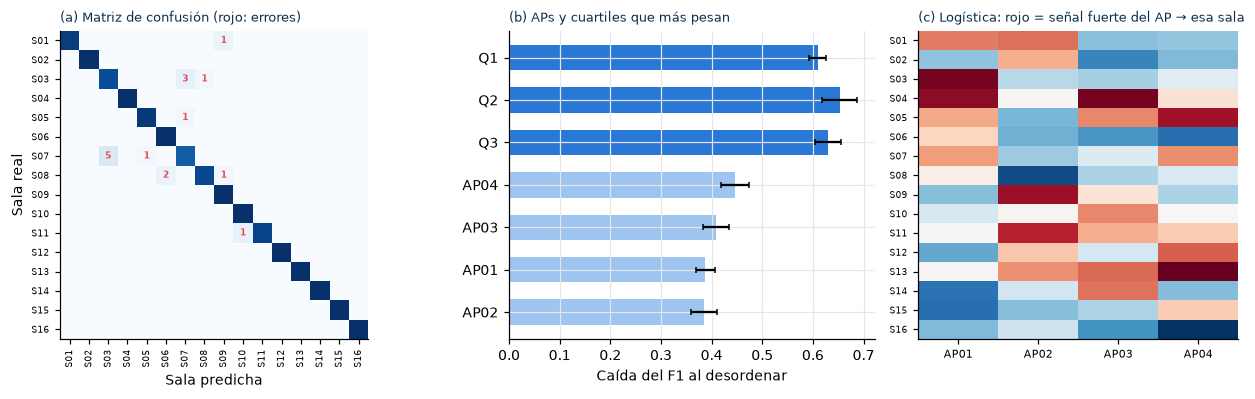

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.7), gridspec_kw=dict(width_ratios=[1.1, 0.8, 0.7]))
cmn = cm / cm.sum(axis=1, keepdims=True)
ax[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax[0].grid(False)
ax[0].set_xticks(range(len(SALAS)), SALAS, fontsize=6, rotation=90); ax[0].set_yticks(range(len(SALAS)), SALAS, fontsize=6)
for i in range(len(SALAS)):
    for j in range(len(SALAS)):
        if cm[i, j] and i != j: ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=6, color="#e34948", weight="bold")
ax[0].set_xlabel("Sala predicha"); ax[0].set_ylabel("Sala real")
ax[0].set_title("(a) Matriz de confusión (rojo: errores)", loc="left", fontsize=8.5, color=TINTA)
o = top_ap[::-1] + ["Q3", "Q2", "Q1"]
v = [imp_ap[k][0] for k in top_ap[::-1]] + [imp_q[k][0] for k in ("Q3", "Q2", "Q1")]
e = [imp_ap[k][1] for k in top_ap[::-1]] + [imp_q[k][1] for k in ("Q3", "Q2", "Q1")]
ax[1].barh(o, v, xerr=e, color=["#9ec5ef"] * len(top_ap) + ["#2a78d6"] * 3, height=0.6, capsize=2)
ax[1].set_xlabel("Caída del F1 al desordenar"); ax[1].set_title("(b) APs y cuartiles que más pesan", loc="left", fontsize=8.5, color=TINTA)
vmax = np.abs(B.values).max()
ax[2].imshow(B.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto"); ax[2].grid(False)
ax[2].set_xticks(range(len(nombres)), nombres, fontsize=7); ax[2].set_yticks(range(len(B.index)), B.index, fontsize=6)
ax[2].set_title("(c) Logística: rojo = señal fuerte del AP → esa sala", loc="left", fontsize=8.5, color=TINTA)
fig.tight_layout(); guardar(fig, "f4_interpretacion"); plt.show()

## 8. Robustez
(a) Si uno de los 4 APs se apaga, deja de detectarse (−100 dBm en sus cuartiles). (b) Con menos escaneos por instancia: el modelo se entrenó con 5 y se prueba agrupando m escaneos de la parte de prueba.

{
 "caida_ap": {
  "AP01": 0.10791366140012572,
  "AP02": 0.1803015474890475,
  "AP03": 0.2066377936280876,
  "AP04": 0.189712347343295
 },
 "escaneos": {
  "1": 0.6942094224960044,
  "2": 0.8454832748196467,
  "3": 0.8957314649974868,
  "5": 0.964180873990276,
  "10": 0.9871587075690491
 },
 "f1_sin_fallas": 0.964180873990276
}


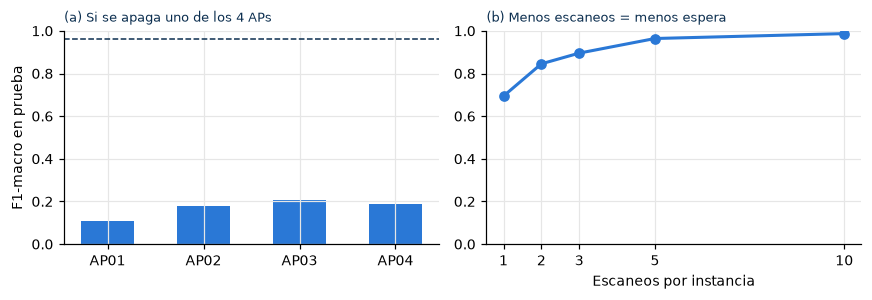

In [15]:
caida_ap = {}
for n in nombres:
    Xc = Xte.copy(); Xc[[f"{n}_Q1", f"{n}_Q2", f"{n}_Q3"]] = NO_DET; caida_ap[n] = float(f1m(yte, mf.predict(Xc)))
escaneos = {}
for m in [1, 2, 3, 5, 10]:
    tm = agrupar(esc_te, m=m); escaneos[m] = float(f1m(tm.sala.to_numpy(dtype=str), mf.predict(tm[FEATS])))
RES["robustez"] = dict(caida_ap=caida_ap, escaneos=escaneos, f1_sin_fallas=float(f1m(yte, ypf)))
print(json.dumps(RES["robustez"], indent=1))
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
ax[0].bar(list(caida_ap), list(caida_ap.values()), color="#2a78d6", width=0.55)
ax[0].axhline(f1m(yte, ypf), color=TINTA, ls="--", lw=1); ax[0].set_ylim(0, 1); ax[0].set_ylabel("F1-macro en prueba")
ax[0].set_title("(a) Si se apaga uno de los 4 APs", loc="left", fontsize=8.5, color=TINTA)
ax[1].plot(list(escaneos), list(escaneos.values()), "o-", color="#2a78d6", lw=2); ax[1].set_xticks(list(escaneos))
ax[1].set_ylim(0, 1); ax[1].set_xlabel("Escaneos por instancia"); ax[1].set_title("(b) Menos escaneos = menos espera", loc="left", fontsize=8.5, color=TINTA)
fig.tight_layout(); guardar(fig, "f5_robustez"); plt.show()

In [16]:
def a_json(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
json.dump(RES, open("resultados_final.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=a_json)
print(sorted(os.listdir("figuras_final")))

['f1_datos.png', 'f2_comparacion.png', 'f3_articulo.png', 'f4_interpretacion.png', 'f5_robustez.png']


## 9. Conclusiones
* **Datos reales.** 10 469 escaneos WiFi en 16 salas del Museo Nacional de Artes Visuales (Montevideo), con 188 APs. Eliminamos 2 030 duplicados exactos (19 %) antes de partir. Solo 20 APs se detectan en la mitad o más de los escaneos.
* **Con los 20 APs frecuentes el problema está resuelto:** todos los modelos logran un F1-macro de 0.996 a 1.000 en prueba.
* **Escenario principal (4 APs, la configuración del mejor resultado del artículo).** El modelo final es **QDA con shrinkage 0.4**, elegido por F1-macro en validación cruzada (0.959 ± 0.007). En prueba logra un F1-macro de 0.964 [0.942–0.981] y un acierto de 95.2 %, frente a 10.9 % de la línea base. Las diferencias con los demás modelos no son significativas en prueba (McNemar, p ≥ 0.58), pero QDA es el **más estable**: queda primero en los 5 agrupamientos de escaneos y en 22 de las 30 combinaciones de 4 APs, con el mínimo más alto (0.870).
* **Supuestos.** Levene rechaza la varianza común en el 100 % de las variables: cada sala tiene su propia dispersión, que es justo lo que modela QDA. El shrinkage es necesario porque algunas salas tienen pocas instancias.
* **Errores.** 16 de 331 instancias de prueba. La mitad son confusiones entre S03 y S07, en ambos sentidos: es probable que sean salas contiguas o abiertas entre sí, aunque el dataset no trae el plano para confirmarlo.
* **Cuartiles.** Resumir escaneos es lo decisivo: con 4 APs, un escaneo suelto logra 0.657 y cinco escaneos resumidos en cuartiles, 0.952. La media rinde igual (0.957), así que los cuartiles no aportan sobre ella.
* **Objetivos del artículo.** El número de APs domina: con 2 APs el acierto es de 0.58–0.66 y con 8 o más, de 0.98 o más; k influye poco. El Método II (centroide) no se puede evaluar porque el dataset no trae coordenadas.
* **Robustez.** Con solo 4 APs el sistema es frágil: si se apaga uno, el F1-macro cae a 0.11–0.21. Con 3 escaneos por instancia ya logra 0.90.